<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/histogram_cdf_esitleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import files
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]
print("Yüklenen dosya:", dosya_adi)

Saving image5.jpeg to image5.jpeg
Yüklenen dosya: image5.jpeg


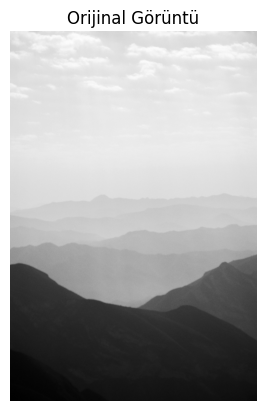

In [3]:
resim = cv2.imread("image5.jpeg", cv2.IMREAD_GRAYSCALE)

plt.imshow(resim, cmap='gray')
plt.title("Orijinal Görüntü")
plt.axis('off')
plt.show()

In [4]:
yukseklik, genislik = resim.shape

histogram = [0] * 256

for i in range(yukseklik):
    for j in range(genislik):

        piksel = resim[i, j]

        histogram[piksel] += 1

print("256 Değerli Histogram:")
print(histogram)

256 Değerli Histogram:
[10, 441, 1747, 2033, 4161, 6863, 5981, 4922, 4735, 4495, 4213, 3194, 2720, 2709, 3507, 5345, 8076, 10226, 10896, 10859, 10828, 10085, 9642, 10686, 11764, 13531, 15383, 16108, 15586, 14587, 14321, 13482, 13294, 12859, 12557, 12215, 11630, 11709, 12056, 12199, 11966, 11457, 10466, 9618, 8699, 7973, 7282, 6837, 5895, 5332, 4693, 3912, 3354, 2857, 2466, 2112, 2149, 2041, 1966, 2014, 1873, 1886, 1760, 1848, 1883, 2001, 2203, 2257, 2469, 2619, 2650, 2689, 2708, 2645, 2759, 2864, 2939, 2867, 2864, 2760, 2675, 2709, 2456, 2426, 2272, 2110, 1832, 1522, 1297, 1081, 896, 835, 697, 641, 569, 534, 486, 462, 425, 383, 291, 261, 235, 195, 160, 109, 137, 120, 126, 92, 89, 110, 80, 94, 111, 104, 84, 128, 106, 82, 107, 107, 132, 97, 112, 116, 126, 144, 117, 164, 183, 259, 365, 448, 698, 898, 1218, 1703, 2047, 2256, 2740, 2849, 3002, 3170, 3347, 3401, 3625, 4029, 4559, 4997, 5939, 7210, 8853, 10144, 11114, 11566, 11507, 11400, 10130, 8703, 6734, 4686, 3089, 2158, 2056, 2321, 2876,

In [5]:
cdf = [0] * 256

cdf[0] = histogram[0]

for i in range(1, 256):

    cdf[i] = cdf[i-1] + histogram[i]

print("Kümülatif Dağılım Değerleri:")
print(cdf)

Kümülatif Dağılım Değerleri:
[10, 451, 2198, 4231, 8392, 15255, 21236, 26158, 30893, 35388, 39601, 42795, 45515, 48224, 51731, 57076, 65152, 75378, 86274, 97133, 107961, 118046, 127688, 138374, 150138, 163669, 179052, 195160, 210746, 225333, 239654, 253136, 266430, 279289, 291846, 304061, 315691, 327400, 339456, 351655, 363621, 375078, 385544, 395162, 403861, 411834, 419116, 425953, 431848, 437180, 441873, 445785, 449139, 451996, 454462, 456574, 458723, 460764, 462730, 464744, 466617, 468503, 470263, 472111, 473994, 475995, 478198, 480455, 482924, 485543, 488193, 490882, 493590, 496235, 498994, 501858, 504797, 507664, 510528, 513288, 515963, 518672, 521128, 523554, 525826, 527936, 529768, 531290, 532587, 533668, 534564, 535399, 536096, 536737, 537306, 537840, 538326, 538788, 539213, 539596, 539887, 540148, 540383, 540578, 540738, 540847, 540984, 541104, 541230, 541322, 541411, 541521, 541601, 541695, 541806, 541910, 541994, 542122, 542228, 542310, 542417, 542524, 542656, 542753, 542865

In [6]:
cdf_min = 0

for i in range(256):
    if cdf[i] > 0:
        cdf_min = cdf[i]
        break

toplam_piksel = yukseklik * genislik

yeni_degerler = [0] * 256

for i in range(256):

    if toplam_piksel != cdf_min:
        yeni_degerler[i] = int(
            ((cdf[i] - cdf_min) / (toplam_piksel - cdf_min)) * 255
        )

yeni_resim = np.zeros((yukseklik, genislik), dtype=np.uint8)

for i in range(yukseklik):
    for j in range(genislik):

        piksel = resim[i, j]

        yeni_resim[i, j] = yeni_degerler[piksel]

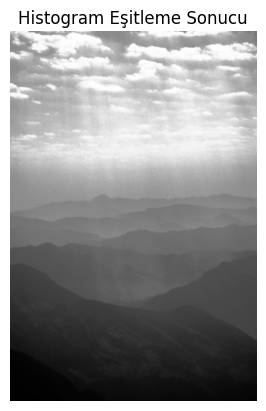

In [7]:
plt.imshow(yeni_resim, cmap='gray')
plt.title("Histogram Eşitleme Sonucu")
plt.axis('off')
plt.show()

In [8]:
cv2.imwrite("histogram_esitlenmis_image5.jpeg", yeni_resim)

print("Histogram eşitleme işlemi tamamlandı.")
print("Çıktı resmi kaydedildi.")

Histogram eşitleme işlemi tamamlandı.
Çıktı resmi kaydedildi.
